# Authenticity Detection of Digital Receipts: VGG19 Classifier

Three-class classifier for GCash and Maya peer-to-peer receipt screenshots: **Authentic**, **Human-Tampered**, **AI-Generated**.

**Pipeline:** frozen VGG19 (ImageNet) as a feature extractor, with a Flatten, Dense 256, Dropout 0.5, Dense 3 softmax head.

**Sections**

1. Setup and configuration
2. Dataset check
3. Dataset standardization
4. Dataset split (70/15/15)
5. Metadata-only baseline
6. Generators and preprocessing preview
7. Model
8. Training
9. Training history
10. Test set evaluation
11. Human-Tampered vs. AI-Generated misclassification analysis
12. Grad-CAM (supplementary)
13. Save run configuration
14. Prototype: upload a receipt and classify it

**Running this notebook**

- Built for Google Colab with a GPU runtime and Google Drive.
- The dataset is **not included** in this repository because real receipts contain personal information. Sections 2 to 13 need your own data in `THESIS/DATASET/<CLASS>/`, with folders `AI_GENERATED`, `AUTHENTIC`, and `HUMAN_TAMPERED`.
- To try the trained model without the dataset, run **Section 1** and then **Section 14**, after placing the `.keras` model file at `MODEL_PATH`.
- Outputs that display real receipt images (the preprocessing preview and the Grad-CAM figures) are cleared in this copy. Re-running those cells will show them.

## 1. Setup and configuration

In [ ]:
!pip install -q split-folders

import os, sys, random, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display
import splitfolders
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus if gpus else 'NONE (Runtime > Change runtime type > GPU)')

Python: 3.13.15
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Change BASE_DIR if your Drive layout is different
BASE_DIR         = '/content/drive/MyDrive/THESIS'
ORIGINAL_DIR     = f'{BASE_DIR}/DATASET'               # DATASET/<class folder>/*.jpg or *.png (never modified)
STANDARDIZED_DIR = f'{BASE_DIR}/DATASET_STANDARDIZED'  # created in Section 3
SPLIT_DIR        = f'{BASE_DIR}/DATASET_SPLIT'         # created in Section 4
OUTPUT_DIR       = f'{BASE_DIR}/OUTPUTS_FinalStandardized'
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_PATH = f'{OUTPUT_DIR}/thesis_model.keras'

# Class folder names inside DATASET (must match exactly)
AI_NAME, AUTH_NAME, TAMP_NAME = 'AI_GENERATED', 'AUTHENTIC', 'HUMAN_TAMPERED'
DISPLAY = {AI_NAME: 'AI-Generated', AUTH_NAME: 'Authentic', TAMP_NAME: 'Human-Tampered'}

# Chapter 3 settings
SEED             = 42
IMG_SIZE         = (448, 224)      # (height, width), the shape fed to the model
BATCH_SIZE       = 32
MAX_EPOCHS       = 10
LEARNING_RATE    = 5e-4
PATIENCE         = 5
DENSE_UNITS      = 256
DROPOUT_RATE     = 0.5
SPLIT_RATIO      = (0.70, 0.15, 0.15)
IMAGES_PER_CLASS = 1000

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# PIL sizes are (width, height), so the canvas is IMG_SIZE reversed
CANVAS_WH = (IMG_SIZE[1], IMG_SIZE[0])   # (224, 448)


def standardize_image(img):
    """Fixed-size RGB canvas: fix EXIF rotation, shrink with Lanczos while keeping the
    aspect ratio (never stretch), then center on a white background.
    Used for the whole dataset (Section 3) and for the prototype (Section 14),
    so uploaded images get exactly the same treatment as the training images."""
    img = ImageOps.exif_transpose(img).convert('RGB')
    img.thumbnail(CANVAS_WH, Image.Resampling.LANCZOS)
    canvas = Image.new('RGB', CANVAS_WH, (255, 255, 255))
    canvas.paste(img, ((CANVAS_WH[0] - img.width) // 2, (CANVAS_WH[1] - img.height) // 2))
    return canvas

## 2. Dataset check
Confirms 1,000 images per class, that every file opens, and reports exact duplicates within each class (report only, nothing is deleted). Runs on the original, unmodified dataset.

In [ ]:
EXTS = ('.jpg', '.jpeg', '.png')
rows, bad_files, dup_groups = [], [], []

for cls in [AI_NAME, AUTH_NAME, TAMP_NAME]:
    folder = os.path.join(ORIGINAL_DIR, cls)
    assert os.path.isdir(folder), f'Missing class folder: {folder}'
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(EXTS))
    hashes, n_bad = {}, 0
    for f in files:
        p = os.path.join(folder, f)
        try:
            with Image.open(p) as im:
                im.verify()
        except Exception:
            bad_files.append(p); n_bad += 1
        with open(p, 'rb') as fh:
            hashes.setdefault(hashlib.md5(fh.read()).hexdigest(), []).append(f)
    dups = [v for v in hashes.values() if len(v) > 1]
    dup_groups += dups
    rows.append({'class': cls, 'images': len(files), 'unreadable': n_bad, 'exact_duplicate_groups': len(dups)})

summary = pd.DataFrame(rows)
display(summary)
assert (summary['images'] == IMAGES_PER_CLASS).all(), 'Each class should have exactly 1,000 images'
assert not bad_files, f'Unreadable images: {bad_files}'
if dup_groups:
    print('Exact duplicates found, review manually:', dup_groups[:5])

            class  images  unreadable  exact_duplicate_groups
0    AI_GENERATED    1000           0                       0
1       AUTHENTIC    1000           0                       0
2  HUMAN_TAMPERED    1000           0                       0

## 3. Dataset standardization
Every image becomes an RGB PNG on a fixed 224 x 448 (W x H) white canvas, aspect ratio preserved, one output image per input image. The original dataset is never modified. If `DATASET_STANDARDIZED` already exists it is reused as is.

In [ ]:
CLASSES = [AI_NAME, AUTH_NAME, TAMP_NAME]
EXTS = ('.jpg', '.jpeg', '.png')
EXPECTED_TOTAL = len(CLASSES) * IMAGES_PER_CLASS

def list_images(folder, exts=EXTS):
    return sorted(f for f in os.listdir(folder)
                  if os.path.isfile(os.path.join(folder, f)) and f.lower().endswith(exts))

original_counts = {c: len(list_images(f'{ORIGINAL_DIR}/{c}')) for c in CLASSES}
assert sum(original_counts.values()) == EXPECTED_TOTAL, f'Expected {EXPECTED_TOTAL} images, found {original_counts}'

if os.path.isdir(STANDARDIZED_DIR):
    print(f'DATASET_STANDARDIZED already exists, reusing it as is:\n{STANDARDIZED_DIR}')
else:
    failed = []
    for cls in CLASSES:
        dst_folder = f'{STANDARDIZED_DIR}/{cls}'
        os.makedirs(dst_folder, exist_ok=True)
        for index, fname in enumerate(list_images(f'{ORIGINAL_DIR}/{cls}')):
            out_name = f'{index:04d}_{os.path.splitext(fname)[0]}.png'   # index prefix keeps names unique
            try:
                with Image.open(f'{ORIGINAL_DIR}/{cls}/{fname}') as img:
                    standardize_image(img).save(f'{dst_folder}/{out_name}', format='PNG')
            except Exception as e:
                failed.append((cls, fname, str(e)))
    if failed:
        raise RuntimeError(f'{len(failed)} images failed, first few: {failed[:5]}. The original dataset was not modified.')
    print('Standardization finished.')

# Verify: same counts as the original, all PNG, RGB, and exactly CANVAS_WH
wrong = []
for cls in CLASSES:
    files = list_images(f'{STANDARDIZED_DIR}/{cls}', exts=('.png',))
    assert len(files) == original_counts[cls], f'{cls}: {len(files)} standardized vs {original_counts[cls]} original'
    for f in files:
        with Image.open(f'{STANDARDIZED_DIR}/{cls}/{f}') as im:
            if im.size != CANVAS_WH or im.mode != 'RGB':
                wrong.append((cls, f, im.size, im.mode))
assert not wrong, f'{len(wrong)} standardized images with wrong size or mode, e.g. {wrong[:3]}'

print(f'Verified: {EXPECTED_TOTAL} PNG images, RGB, {CANVAS_WH[0]} x {CANVAS_WH[1]} (W x H). Original dataset untouched.')

## 4. Dataset split (70/15/15, stratified per class)

In [ ]:
if os.path.isdir(SPLIT_DIR) and os.listdir(SPLIT_DIR):
    print('DATASET_SPLIT already exists, reusing it. Delete the folder first if it is left over from an older dataset.')
else:
    splitfolders.ratio(STANDARDIZED_DIR, output=SPLIT_DIR, seed=SEED, ratio=SPLIT_RATIO, move=False)

classes = [AI_NAME, AUTH_NAME, TAMP_NAME]
split_df = pd.DataFrame({s: {c: len(os.listdir(f'{SPLIT_DIR}/{s}/{c}')) for c in classes} for s in ['train', 'val', 'test']}).T
split_df['total'] = split_df.sum(axis=1)
display(split_df)   # Table 3
assert split_df['total'].tolist() == [2100, 450, 450], 'Split sizes do not match Table 3'

DATASET_SPLIT already exists, reusing it. Delete the folder first if it is left over from an older dataset.


       AI_GENERATED  AUTHENTIC  HUMAN_TAMPERED  total
train           700        700             700   2100
val             150        150             150    450
test            150        150             150    450

## 5. Metadata-only baseline
Trains a Random Forest on file properties only (width, height, aspect ratio, file size, extension) to check how much of the task can be solved without looking at pixels. Used as a sanity check for shortcut cues, not as a model of the study.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

names = sorted(os.listdir(f'{SPLIT_DIR}/train'))
COLS = ['width', 'height', 'aspect', 'bytes', 'is_jpg']

def meta(subset):
    X, y = [], []
    for ci, cname in enumerate(names):
        folder = f'{SPLIT_DIR}/{subset}/{cname}'
        for f in os.listdir(folder):
            p = os.path.join(folder, f)
            try:
                with Image.open(p) as im:
                    w, h = im.size
            except Exception as e:
                print(f'Warning: Skipping unreadable file {p} due to error: {e}')
                continue
            ext_jpg = os.path.splitext(f)[1].lower() in ('.jpg', '.jpeg')
            X.append([w, h, w / h, os.path.getsize(p), ext_jpg])
            y.append(ci)
    return np.array(X, dtype=float), np.array(y)

Xtr, ytr = meta('train')
Xva, yva = meta('val')

# All five metadata features
clf = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xtr, ytr)
print('Metadata-only val accuracy (all features):',
      round(accuracy_score(yva, clf.predict(Xva)), 4), '(chance = 0.333)')

# File size only
b = COLS.index('bytes')
clf_b = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xtr[:, [b]], ytr)
print('Metadata-only val accuracy (file size only):',
      round(accuracy_score(yva, clf_b.predict(Xva[:, [b]])), 4), '(chance = 0.333)')

df = pd.DataFrame(Xtr, columns=COLS)
df['class'] = [names[i] for i in ytr]
display(df.groupby('class')[['width', 'height', 'bytes']].agg(['median', 'min', 'max']))
print(df.groupby('class')[['width', 'height']].nunique())   # distinct sizes per class

Metadata-only val accuracy (all features): 0.82 (chance = 0.333)
Metadata-only val accuracy (file size only): 0.82 (chance = 0.333)


                width               height                  bytes           \
               median    min    max median    min    max   median      min   
class                                                                        
AI_GENERATED    224.0  224.0  224.0  448.0  448.0  448.0  80393.0  25483.0   
AUTHENTIC       224.0  224.0  224.0  448.0  448.0  448.0  28970.0  20879.0   
HUMAN_TAMPERED  224.0  224.0  224.0  448.0  448.0  448.0  28186.5  25877.0   

                          
                     max  
class                     
AI_GENERATED    120703.0  
AUTHENTIC        80801.0  
HUMAN_TAMPERED   41955.0  

                width  height
class                        
AI_GENERATED        1       1
AUTHENTIC           1       1
HUMAN_TAMPERED      1       1


## 6. Generators and preprocessing preview
VGG19 `preprocess_input` on all subsets. No data augmentation. Labels come from folder names as one-hot vectors, ordered alphabetically (`AI_GENERATED`, `AUTHENTIC`, `HUMAN_TAMPERED`).

In [ ]:
datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = datagen.flow_from_directory(
    f'{SPLIT_DIR}/train', target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True, seed=SEED)
val_gen = datagen.flow_from_directory(
    f'{SPLIT_DIR}/val', target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False)
test_gen = datagen.flow_from_directory(
    f'{SPLIT_DIR}/test', target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False)   # shuffle=False keeps predictions aligned with labels

assert train_gen.class_indices == val_gen.class_indices == test_gen.class_indices
CLASS_NAMES = [n for n, _ in sorted(train_gen.class_indices.items(), key=lambda kv: kv[1])]
print(train_gen.class_indices)   # expected order: AI_GENERATED, AUTHENTIC, HUMAN_TAMPERED

Found 2100 images belonging to 3 classes.
Found 450 images belonging to 3 classes.
Found 450 images belonging to 3 classes.
{'AI_GENERATED': 0, 'AUTHENTIC': 1, 'HUMAN_TAMPERED': 2}


In [ ]:
# Preprocessing preview: original -> resized -> preprocess_input
rng = np.random.default_rng(SEED)
col_titles = ['Original', f'Resized to {IMG_SIZE[0]} x {IMG_SIZE[1]} (H x W)',
              'After preprocess_input\n(rescaled for display)']

fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(11, 10.5))
for r, cname in enumerate(CLASS_NAMES):
    folder = f'{SPLIT_DIR}/train/{cname}'
    fname = str(rng.choice(sorted(os.listdir(folder))))
    path = os.path.join(folder, fname)

    original = Image.open(path).convert('RGB')
    resized = np.array(tf.keras.utils.load_img(path, target_size=IMG_SIZE))   # same loader as the generators
    processed = preprocess_input(resized.astype('float32').copy())
    shown = (processed - processed.min()) / (processed.max() - processed.min())

    for c, im in enumerate([np.array(original), resized, shown]):
        ax = axes[r, c]
        ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(col_titles[c], fontsize=10)
    axes[r, 0].set_ylabel(DISPLAY[cname], fontsize=11)
    axes[r, 0].set_xlabel(f'{original.size[0]} x {original.size[1]} px', fontsize=9)

    print(f'{DISPLAY[cname]:15s} | {fname} | resized range: {resized.min()}-{resized.max()} '
          f'| after preprocess_input: {processed.min():.1f} to {processed.max():.1f}')

plt.suptitle('Preprocessing pipeline preview (training subset)', fontsize=13)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/preprocessing_preview.png', dpi=200)
plt.show()

## 7. Model
Frozen VGG19 base (ImageNet), then Flatten, Dense 256 ReLU, Dropout 0.5, Dense 3 Softmax. Built with the functional API on top of `base_model.output` so the last conv layer stays accessible for Grad-CAM.

In [ ]:
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

x = layers.Flatten(name='flatten')(base_model.output)                       # 14 x 7 x 512 -> 50,176 at 448 x 224 input
x = layers.Dense(DENSE_UNITS, activation='relu', name='dense_256')(x)
x = layers.Dropout(DROPOUT_RATE, name='dropout')(x)
outputs = layers.Dense(len(CLASS_NAMES), activation='softmax', name='softmax_output')(x)

model = models.Model(inputs=base_model.input, outputs=outputs, name='vgg19_receipt_classifier')
model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
frozen = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
print(f'Trainable params: {trainable:,} | Frozen params: {frozen:,}')

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg19_receipt_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 448, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 448, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 448, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 224, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 224, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 224, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 112, 56, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 112, 56, 256)   │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 112, 56, 256)   │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 112, 56, 256)   │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 112, 56, 256)   │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 56, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 56, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 56, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 56, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 56, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 28, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 28, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 28, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 28, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 28, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 14, 7, 512)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             

 Total params: 32,870,467 (125.39 MB)

 Trainable params: 12,846,083 (49.00 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

Trainable params: 12,846,083 | Frozen params: 20,024,384


## 8. Training
`ModelCheckpoint` keeps the best `val_accuracy`. `EarlyStopping` (patience 5) restores the best epoch.

In [ ]:
checkpoint = ModelCheckpoint(MODEL_PATH, monitor='val_accuracy', mode='max',
                             save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='val_accuracy', mode='max', patience=PATIENCE,
                           restore_best_weights=True, verbose=1)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=MAX_EPOCHS,
    callbacks=[checkpoint, early_stop])

hist_df = pd.DataFrame(history.history)
hist_df.index.name = 'epoch'
hist_df.to_csv(f'{OUTPUT_DIR}/training_history.csv')
display(hist_df.round(4))

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.5641 - loss: 17.4774
Epoch 1: val_accuracy improved from None to 0.79111, saving model to /content/drive/MyDrive/THESIS/OUTPUTS_standardizedFinal/thesis_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/THESIS/OUTPUTS_standardizedFinal/thesis_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 48s 562ms/step - accuracy: 0.6700 - loss: 7.9059 - val_accuracy: 0.7911 - val_loss: 0.5945
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.7569 - loss: 0.6689
Epoch 2: val_accuracy improved from 0.79111 to 0.88000, saving model to /content/drive/MyDrive/THESIS/OUTPUTS_standardizedFinal/thesis_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/THESIS/OUTPUTS_standardizedFinal/thesis_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 28s 425ms/step - accuracy: 0.7657 - loss: 0.6033 - val_accuracy: 0.8800 - val_loss: 0.3926
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step - accuracy: 0.7864 - loss: 0

       accuracy    loss  val_accuracy  val_loss
epoch                                          
0        0.6700  7.9059        0.7911    0.5945
1        0.7657  0.6033        0.8800    0.3926
2        0.7948  0.4718        0.8733    0.3978
3        0.7933  0.4707        0.8911    0.3939
4        0.8057  0.4218        0.8889    0.3177
5        0.8114  0.4108        0.9044    0.3322
6        0.8357  0.3820        0.8756    0.3395
7        0.8271  0.3808        0.8667    0.3499
8        0.8333  0.3608        0.9178    0.3085
9        0.8414  0.3495        0.9422    0.3389

## 9. Training history

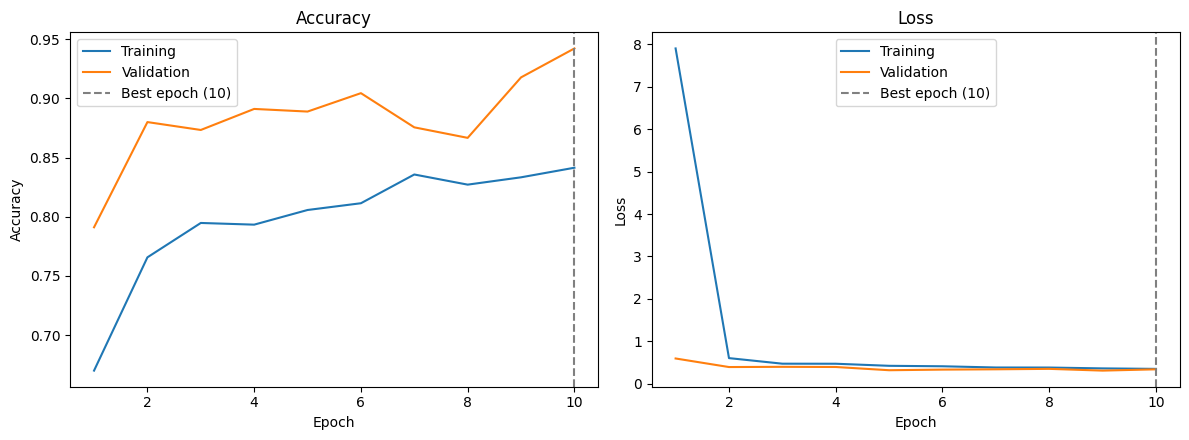

In [ ]:
best_epoch = int(hist_df['val_accuracy'].idxmax())
ep = np.arange(1, len(hist_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(ep, hist_df['accuracy'], label='Training')
axes[0].plot(ep, hist_df['val_accuracy'], label='Validation')
axes[0].axvline(best_epoch + 1, color='gray', ls='--', label=f'Best epoch ({best_epoch + 1})')
axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].legend()

axes[1].plot(ep, hist_df['loss'], label='Training')
axes[1].plot(ep, hist_df['val_loss'], label='Validation')
axes[1].axvline(best_epoch + 1, color='gray', ls='--', label=f'Best epoch ({best_epoch + 1})')
axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_history.png', dpi=200)
plt.show()

## 10. Test set evaluation
Reloads the best checkpoint, then computes accuracy, per-class precision, recall, F1, and the confusion matrix on the 450 test images.

15/15 ━━━━━━━━━━━━━━━━━━━━ 164s 12s/step
Test accuracy: 0.9489 | Test loss: 0.3498
                precision    recall  f1-score   support

  AI-Generated     0.9789    0.9267    0.9521       150
     Authentic     0.9051    0.9533    0.9286       150
Human-Tampered     0.9667    0.9667    0.9667       150

      accuracy                         0.9489       450
     macro avg     0.9502    0.9489    0.9491       450
  weighted avg     0.9502    0.9489    0.9491       450



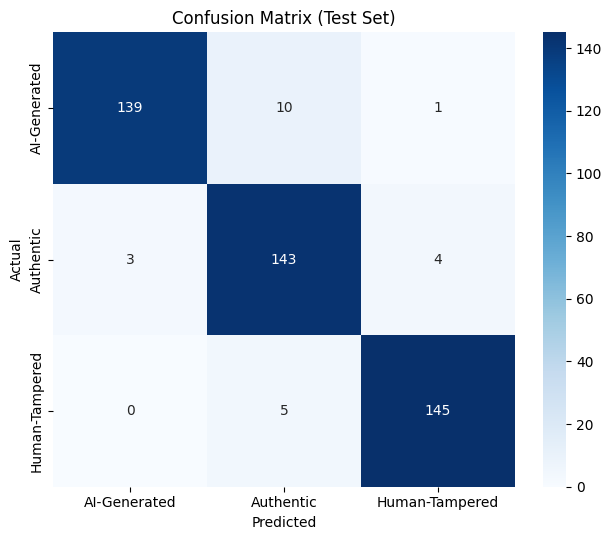

In [ ]:
best_model = tf.keras.models.load_model(MODEL_PATH)

test_gen.reset()
probs = best_model.predict(test_gen, verbose=1)
y_pred = np.argmax(probs, axis=1)
y_true = test_gen.classes

test_acc = float(np.mean(y_pred == y_true))
test_loss = float(best_model.evaluate(test_gen, verbose=0)[0])
print(f'Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}')

# Table 6: classification report
display_names = [DISPLAY[c] for c in CLASS_NAMES]
report = classification_report(y_true, y_pred, target_names=display_names, digits=4, output_dict=True)
report_df = pd.DataFrame(report).T
report_df.to_csv(f'{OUTPUT_DIR}/classification_report.csv')
print(classification_report(y_true, y_pred, target_names=display_names, digits=4))

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, index=display_names, columns=display_names)
cm_df.to_csv(f'{OUTPUT_DIR}/confusion_matrix.csv')

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix.png', dpi=200)
plt.show()

## 11. Human-Tampered vs. AI-Generated misclassification analysis (Table 7)

In [ ]:
idx = {n: i for i, n in enumerate(CLASS_NAMES)}
i_ai, i_au, i_ht = idx[AI_NAME], idx[AUTH_NAME], idx[TAMP_NAME]

n_ai, n_ht = cm[i_ai].sum(), cm[i_ht].sum()
a = int(cm[i_ht, i_ai])      # human-tampered predicted as AI-generated
b = int(cm[i_ai, i_ht])      # AI-generated predicted as human-tampered
correct_ht, correct_ai = int(cm[i_ht, i_ht]), int(cm[i_ai, i_ai])
missed = int(cm[i_ht, i_au] + cm[i_ai, i_au])     # forgeries predicted as authentic

denom_type = correct_ht + correct_ai + a + b
analysis = pd.DataFrame([
    ['a: Human-Tampered predicted as AI-Generated', a, f'{a} of {n_ht}'],
    ['b: AI-Generated predicted as Human-Tampered', b, f'{b} of {n_ai}'],
    ['False AI-generated rate (a / n_ht)', a / n_ht, f'{a} / {n_ht}'],
    ['False human-tampered rate (b / n_ai)', b / n_ai, f'{b} / {n_ai}'],
    ['Forgery-type accuracy', (correct_ht + correct_ai) / denom_type,
        f'({correct_ht} + {correct_ai}) / {denom_type}'],
    ['Forgery miss rate', missed / (n_ht + n_ai), f'{missed} / {n_ht + n_ai}'],
], columns=['Measure', 'Value', 'Computation'])
display(analysis)
analysis.to_csv(f'{OUTPUT_DIR}/forgery_misclassification_analysis.csv', index=False)

                                       Measure     Value        Computation
0  a: Human-Tampered predicted as AI-Generated  0.000000           0 of 150
1  b: AI-Generated predicted as Human-Tampered  1.000000           1 of 150
2           False AI-generated rate (a / n_ht)  0.000000            0 / 150
3         False human-tampered rate (b / n_ai)  0.006667            1 / 150
4                        Forgery-type accuracy  0.996491  (145 + 139) / 285
5                            Forgery miss rate  0.050000           15 / 300

## 12. Grad-CAM (supplementary)
Heatmaps from the last convolutional layer (`block5_conv4`) for correctly and incorrectly classified test images of each class. Qualitative only, no effect on the reported metrics. Output cleared in this copy because the figures show real receipts.

In [ ]:
LAST_CONV = 'block5_conv4'
grad_model = tf.keras.models.Model(
    best_model.input,
    [best_model.get_layer(LAST_CONV).output, best_model.output])

def gradcam(x):
    x = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:
        tape.watch(x)   # base is frozen, so watch the input to keep the graph recorded
        conv_out, preds = grad_model(x)
        cls = tf.argmax(preds[0])
        score = preds[:, cls]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_out * weights[:, tf.newaxis, tf.newaxis, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), preds.numpy()[0]

def overlay(img_arr, cam, alpha=0.4):
    cam_r = tf.image.resize(cam[..., np.newaxis], IMG_SIZE).numpy()[..., 0]
    heat = plt.cm.jet(cam_r)[..., :3]
    return np.clip((1 - alpha) * (img_arr / 255.0) + alpha * heat, 0, 1)

paths = np.array(test_gen.filepaths)
rng = np.random.default_rng(SEED)
N_PER_GROUP = 3

def pick(true_idx, correct):
    same = (y_pred == y_true) if correct else (y_pred != y_true)
    ids = np.where((y_true == true_idx) & same)[0]
    return rng.choice(ids, size=min(N_PER_GROUP, len(ids)), replace=False) if len(ids) else []

for ci, cname in enumerate(CLASS_NAMES):
    fig, axes = plt.subplots(2, N_PER_GROUP, figsize=(4 * N_PER_GROUP, 9))
    for r, correct in enumerate([True, False]):
        ids = pick(ci, correct)
        for c in range(N_PER_GROUP):
            ax = axes[r, c]; ax.axis('off')
            if c >= len(ids):
                if c == 0:
                    ax.text(0.5, 0.5, 'No samples', ha='center', va='center')
                continue
            i = ids[c]
            img = np.array(tf.keras.utils.load_img(paths[i], target_size=IMG_SIZE))
            x = preprocess_input(img[np.newaxis].astype('float32').copy())
            cam, p = gradcam(x)
            pred = int(np.argmax(p))
            ax.imshow(overlay(img, cam))
            ax.set_title(f"{'Correct' if correct else 'Wrong'}\nTrue: {DISPLAY[cname]}\n"
                         f"Pred: {DISPLAY[CLASS_NAMES[pred]]} ({p[pred]:.2f})", fontsize=9)
    plt.suptitle(f'Grad-CAM: actual class {DISPLAY[cname]}', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/gradcam_{cname.lower()}.png', dpi=200)
    plt.show()

## 13. Save run configuration

In [ ]:
run_info = {
    'tensorflow': tf.__version__, 'seed': SEED, 'img_size': IMG_SIZE, 'batch_size': BATCH_SIZE,
    'max_epochs': MAX_EPOCHS, 'epochs_run': len(hist_df), 'best_epoch': best_epoch + 1,
    'learning_rate': LEARNING_RATE, 'patience': PATIENCE, 'dense_units': DENSE_UNITS,
    'dropout': DROPOUT_RATE, 'split': SPLIT_RATIO, 'class_indices': train_gen.class_indices,
    'test_accuracy': test_acc, 'test_loss': test_loss,
}
with open(f'{OUTPUT_DIR}/run_info.json', 'w') as f:
    json.dump(run_info, f, indent=2)
print(json.dumps(run_info, indent=2))

{
  "tensorflow": "2.21.0",
  "seed": 42,
  "img_size": [
    448,
    224
  ],
  "batch_size": 32,
  "max_epochs": 10,
  "epochs_run": 10,
  "best_epoch": 10,
  "learning_rate": 0.0005,
  "patience": 5,
  "dense_units": 256,
  "dropout": 0.5,
  "split": [
    0.7,
    0.15,
    0.15
  ],
  "class_indices": {
    "AI_GENERATED": 0,
    "AUTHENTIC": 1,
    "HUMAN_TAMPERED": 2
  },
  "test_accuracy": 0.9488888888888889,
  "test_loss": 0.34977754950523376
}


## 14. Prototype: upload a receipt and classify it

Run the cell, choose one or more receipt screenshots, and read the prediction. Run it again to test more images.

- Works right after training (uses `best_model`), or on its own: run Section 1, then this cell. It then loads the saved model from `MODEL_PATH`.
- Uploads go through the same `standardize_image` function as the training data.
- The model only knows GCash and Maya peer-to-peer receipts. Any other image still gets one of the three labels, so a prediction on an out-of-scope image means nothing.

In [ ]:
import io
from google.colab import files

# Use the model from training if it is in memory, otherwise load the saved file
demo_model = best_model if 'best_model' in globals() else tf.keras.models.load_model(MODEL_PATH)

# flow_from_directory sorts class folders alphabetically, so the output order is fixed
DEMO_LABELS = [DISPLAY[c] for c in sorted([AI_NAME, AUTH_NAME, TAMP_NAME])]


def classify_receipt(img, name='uploaded image'):
    shown = standardize_image(img)                                     # what the model actually sees
    x = preprocess_input(np.array(shown, dtype='float32')[np.newaxis]) # same preprocessing as training
    probs = demo_model.predict(x, verbose=0)[0]
    top = int(np.argmax(probs))

    fig, ax = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [1, 1.4]})
    ax[0].imshow(shown); ax[0].axis('off'); ax[0].set_title('Input (as the model sees it)')
    bars = ax[1].barh(DEMO_LABELS, probs, color='#4C72B0')
    bars[top].set_color('#C44E52')
    ax[1].set_xlim(0, 1.1); ax[1].set_xlabel('Probability'); ax[1].invert_yaxis()
    for i, p in enumerate(probs):
        ax[1].text(p + 0.02, i, f'{p:.1%}', va='center')
    fig.suptitle(f'{name}: {DEMO_LABELS[top]} ({probs[top]:.1%})', fontsize=13)
    plt.tight_layout()
    plt.show()
    return dict(zip(DEMO_LABELS, probs.round(4)))


uploaded = files.upload()
for fname, data in uploaded.items():
    classify_receipt(Image.open(io.BytesIO(data)), fname)